In [177]:
# importamos librerías

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [178]:
# cargamos archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [179]:
# mostramos las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [180]:
# mostramos las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [181]:
# mostramos las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [182]:
# revisamos el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [183]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [184]:
users.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [185]:
usage.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


PROBLEMAS QUE DETECTAMOS 

#Dataset users
- city: tiene 469 valores nulos (4.000 − 3.531).
- churn_date: tiene 3.534 valores nulos (4.000 − 466).
- reg_date: es de tipo object; probablemente debamos convertirla a fecha.



#Dataset usage
- date: tiene 50 valores nulos.
- duration: tiene 22.076 valores nulos.
- length: tiene 17.896 valores nulos.
- date es de tipo object; debemos revisar su formato y convertirla a fecha.



#Dataset plans
No presenta valores nulos. Los tipos numéricos de precios, minutos y mensajes parecen adecuados para comenzar.




In [186]:
# cantidad de nulos para users
print('CANTIDAD DE NULOS USERS')
print(users.isna().sum())
print()
print('PORCENTAJE DE NULOS USERS')
print(users.isna().mean()*100)

CANTIDAD DE NULOS USERS
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

PORCENTAJE DE NULOS USERS
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [187]:
# cantidad de nulos para usage
print('CANTIDAD DE NULOS USAGE')
print(usage.isna().sum())
print()
print('PORCENTAJE DE NULOS DE USAGE')
print(usage.isna().mean()*100)

CANTIDAD DE NULOS USAGE
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

PORCENTAJE DE NULOS DE USAGE
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


In [188]:
# exploramos columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000



-La columna user_id presenta valores consecutivos entre 10000 y 13999, sin anomalías evidentes en sus estadísticas descriptivas. Como se trata de identificadores, la media y la desviación estándar no son relevantes para analizar el comportamiento de los usuarios.

-La columna age presenta un valor mínimo de -999, que es inválido para representar una edad y podría corresponder a un sentinel. Este valor afecta las estadísticas descriptivas: la media es de 33,74 años y la desviación estándar es de 123,23, valores distorsionados por ese registro. Será necesario investigar los valores inválidos antes de continuar con el análisis.

In [189]:
# exploramos columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


-Las columnas `id` y `user_id` presentan rangos aparentemente coherentes con su función de identificadores. La columna id va de 1 a 40000, mientras que user_id contiene valores entre 10000 y 13999, dentro del rango observado en el dataset de usuarios.

-Las columnas `duration` y `length` presentan valores mínimos de 0 y máximos de 120 y 1490, respectivamente. El valor máximo de length destaca frente a sus percentiles y podría ser un valor atípico. Es necesario revisar los valores extremos, los ceros y los posibles valores inválidos antes de decidir si requieren tratamiento.

In [190]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for columna in columnas_user:
    print(f"\nValores únicos de {columna}:")
    print(users[columna].value_counts(dropna=False))



Valores únicos de city:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores únicos de plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64



-La columna `city` presenta siete categorías visibles, incluyendo el valor ? en 96 registros y 469 valores nulos. El símbolo ? funciona como un posible sentinel que representa una ciudad desconocida, por lo que deberá convertirse en un valor nulo para unificar el tratamiento de los datos faltantes.

-La columna `plan` contiene dos categorías: Basico (2595 usuarios) y Premium (1405 usuarios). No se observan categorías inesperadas ni diferencias de escritura en los resultados obtenidos.

In [191]:


# explorar columna categórica de usage
columnas_usage = ['type'] # completa el código
for columna in columnas_usage:
    print(f"\nValores únicos de {columna}:")
    print(usage[columna].value_counts(dropna=False))

    


Valores únicos de type:
text    22092
call    17908
Name: type, dtype: int64


- La columna `type` presenta dos categorías: text, con 22.092 registros, y call, con 17.908 registros. No se observan categorías inesperadas ni valores nulos en esta columna. Ambos valores son coherentes con los tipos de uso que registra el dataset: mensajes de texto y llamadas.


---
✍️ **Comentario**:

**Valores inválidos o sentinels**  

-Columna age de users: se identificó el valor -999, que no es válido para representar una edad y podría ser un sentinel. Recomiendo investigar los registros afectados y reemplazar este valor por NaN si se confirma que representa un dato faltante.

-Columna city de users: se encontraron 96 registros con el símbolo ? y 469 valores nulos. El símbolo podría representar una ciudad desconocida. Recomiendo reemplazar ? por NaN para unificar el tratamiento de los datos faltantes, sin asignar ciudades arbitrariamente.

-Columnas duration y length de usage: se observaron valores mínimos de cero y máximos de 120 y 1490, respectivamente. Estos valores extremos requieren investigación, pero no se pueden clasificar como inválidos únicamente a partir de las estadísticas descriptivas. Recomiendo revisar los registros antes de decidir si necesitan corrección o tratamiento.

-Resto de las columnas analizadas: no se detectaron valores categóricos inesperados en plan ni en type. Los identificadores id y user_id presentan rangos aparentemente coherentes con su función. 

In [192]:
# Convertimos a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [193]:
# Convertimos a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [194]:
# Revisamos los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, se observa que los registros corresponden principalmente a los años 2022, 2023 y 2024, con 1314, 1316 y 1330 registros, respectivamente. Sin embargo, se identificaron 40 registros con fechas de alta en 2026, un año fuera del período de datos establecido para el proyecto (hasta 2024). Se recomienda investigar estos registros y determinar cómo tratarlos antes de continuar con el análisis.

In [195]:
# Revisamos los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64

En `date`, los 39.950 registros con fecha válida corresponden al año 2024, dentro del período establecido para el análisis. Se identificaron además 50 valores nulos, que deberán tenerse en cuenta al trabajar con información temporal. No se detectaron años fuera de rango entre las fechas válidas. Basaremos el análisis en los registros de 2024 con fechas válidas.

✍️ **Comentario**:

**Fechas fuera de rango**  

Columna reg_date de users: se identificaron 40 registros correspondientes al año 2026, aunque el período de datos del proyecto llega hasta 2024. Estas fechas están fuera del rango esperado y podrían deberse a errores de captura. Recomiendo revisar los registros afectados y verificar si existe información que permita corregirlos. Si no es posible confirmar las fechas correctas, conservarlas identificadas como inválidas o excluirlas de los análisis temporales que requieran fechas válidas, documentando la decisión.

Columna date de usage: los 39.950 registros con fecha válida corresponden al año 2024, dentro del período establecido. También se identificaron 50 valores nulos, que deberán considerarse en los análisis temporales. No se detectaron años fuera de rango entre las fechas válidas.

Acción general: mantener las fechas correctamente interpretadas como datetime, investigar los registros fuera del período esperado y evitar modificar fechas sin evidencia que permita determinar su valor correcto.

In [196]:
# Reemplazamos -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median() ##MEDIANA entre todos los valores que SON DISTINTOS a -999
users['age'] = users['age'].replace(-999, age_mediana)

# Verificamos cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [197]:
# Reemplazamos ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)


# Verificamos cambios
users['city'].value_counts(dropna=False)


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [198]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


**Comentario:**
- En la columna city, se reemplazaron los 96 valores "?" por valores nulos (pd.NA). Como resultado, los valores nulos aumentaron de 469 a 565. Se conservaron las ciudades conocidas sin modificaciones y se unificó el tratamiento de los registros cuya ciudad es desconocida.

In [199]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().sum())

type
call        0
text    22076
Name: duration, dtype: int64

In [200]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().sum())

type
call    17896
text        0
Name: length, dtype: int64

Diagnóstico de nulos en duration y length

-duration: se encontraron 22.076 valores nulos en los registros de tipo text y ningún valor nulo en los registros de tipo call. Esto indica que los nulos dependen del tipo de registro, ya que la duración corresponde a las llamadas y no aplica a los mensajes.

-length: se encontraron 17.896 valores nulos en los registros de tipo call y ningún valor nulo en los registros de tipo text. Esto indica que la longitud corresponde a los mensajes y no aplica a las llamadas.

*Acción recomendada: conservar los valores nulos en ambas columnas, sin imputarlos ni eliminar registros, porque representan valores no aplicables según el tipo de uso. La comprobación confirma una relación directa entre type y los nulos observados; técnicamente, se trata de nulos estructurales más que de datos faltantes MAR en sentido estadístico estricto.

In [201]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocemos el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocemos el total de llamadas


# Agrupamos información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes = ("is_text", "sum"),
    cant_llamadas = ("is_call", "sum"),
    cant_minutos_llamada = ("duration", "sum")
).reset_index()

# observamos el resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [202]:

# Combinamos la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


In [203]:

# Resumen estadístico de las columnas numéricas
user_profile.describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3959.000000,3959.000000,3959.000000
mean,5.525385,4.483708,23.331074
std,2.359503,2.143459,18.199917
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.790000
75%,7.000000,6.000000,31.405000
max,17.000000,15.000000,155.690000


Resumen estadístico de uso por usuario

Durante 2024, los usuarios registraron un promedio de 5,53 mensajes, 4,48 llamadas y 23,33 minutos de llamadas. Las medianas fueron de 5 mensajes, 4 llamadas y 19,79 minutos, respectivamente. La diferencia entre la media y la mediana de los minutos de llamadas, junto con un máximo de 155,69 minutos, sugiere que podría haber usuarios con un consumo superior al habitual, por lo que conviene revisar la distribución de esta variable más adelante.

Se observan valores mínimos de cero en las tres métricas, compatibles con usuarios que no utilizaron alguno de estos servicios durante el período. Además, 3.959 usuarios tienen registros de uso agregados; es necesario considerar que los usuarios sin registros pueden tener métricas faltantes.

In [204]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.974747
Premium    35.025253
Name: plan, dtype: float64

Distribución porcentual del tipo de plan

El 64,97% de los usuarios tiene contratado el plan Básico, mientras que el 35,03% utiliza el plan Premium. Esto muestra una mayor concentración de clientes en el plan Básico, con una diferencia de aproximadamente 29,95 puntos porcentuales entre ambos planes. Esta distribución permite identificar cuál es el plan predominante en la base de usuarios, aunque no permite concluir por sí sola cuál es más rentable para la empresa.

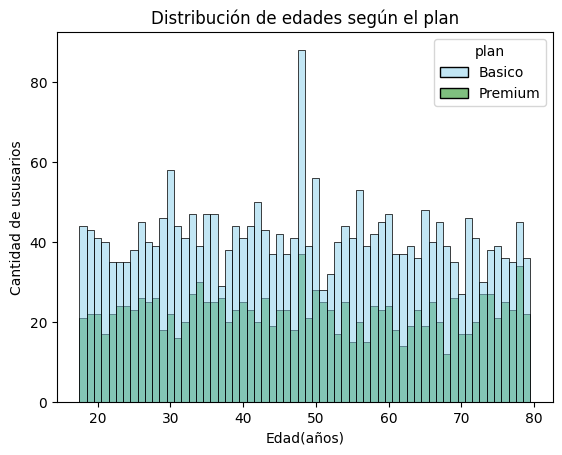

In [205]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de edades según el plan')
plt.xlabel('Edad(años)')
plt.ylabel('Cantidad de ususarios')
plt.show()

💡Insights - Edad de los usuarios

Las edades presentan una distribución relativamente uniforme entre los 18 y los 79 años, sin una concentración dominante en un único rango ni un sesgo evidente hacia las edades más altas o más bajas. Los usuarios del plan Básico muestran frecuencias absolutas superiores en la mayoría de los rangos, lo que puede explicarse por su mayor presencia en la base de clientes. Visualmente, no se observa una diferencia marcada en la distribución de edades entre los dos planes.

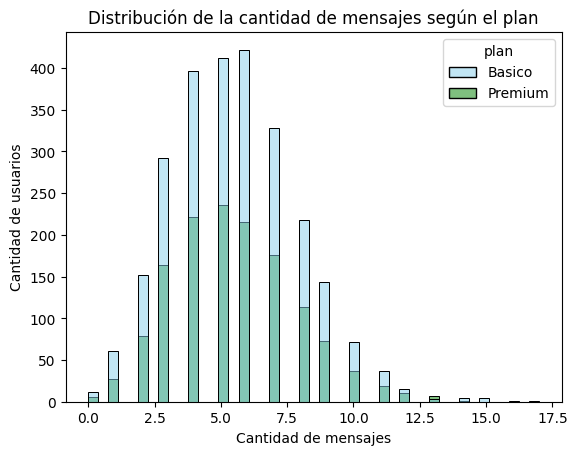

In [206]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de la cantidad de mensajes según el plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights - Cantidad de mensajes

La distribución de la cantidad de mensajes se concentra principalmente entre 3 y 7 mensajes por usuario, con un pico alrededor de 5–6. Presenta un sesgo hacia la derecha, ya que la frecuencia disminuye a medida que aumenta la cantidad de mensajes. Ambos planes muestran una forma de distribución similar. El plan Básico presenta mayores frecuencias absolutas, lo que es coherente con su mayor participación en la base de clientes; por lo tanto, el gráfico no permite concluir por sí solo que sus usuarios envíen más mensajes individualmente.

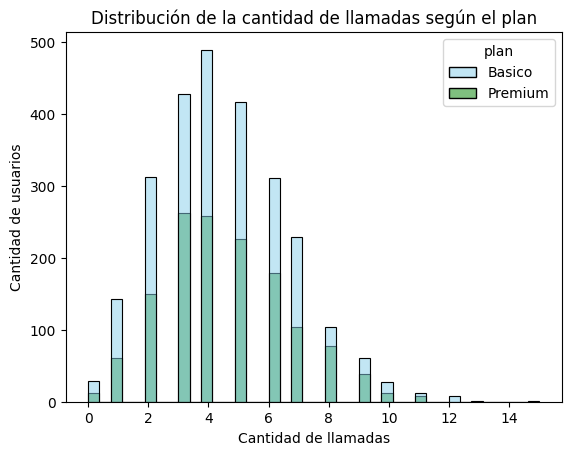

In [207]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de la cantidad de llamadas según el plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights -  Cantidad de llamadas

La cantidad de llamadas se concentra principalmente entre 2 y 6 por usuario, con un máximo de frecuencia alrededor de 4 llamadas. La distribución presenta un sesgo hacia la derecha, debido a que la cantidad de usuarios disminuye para frecuencias de llamadas más elevadas. Ambos planes muestran un patrón similar, aunque el plan Básico tiene mayores frecuencias absolutas. Esto no implica necesariamente que sus clientes realicen más llamadas por persona, ya que también hay más usuarios con ese plan. 

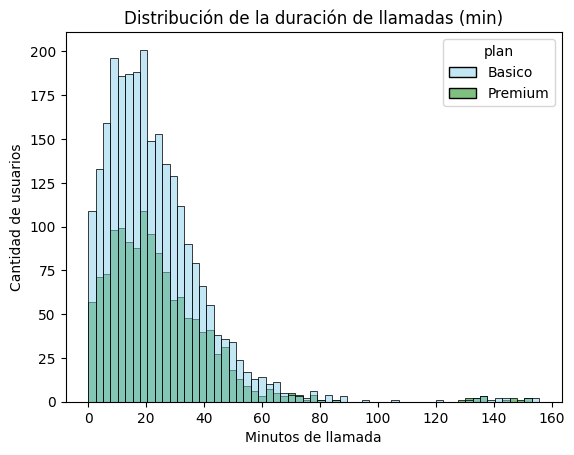

In [208]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de la duración de llamadas (min)')
plt.xlabel('Minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights - Minutos de llamadas

La distribución de los minutos de llamadas presenta un marcado sesgo hacia la derecha. La mayoría de los usuarios registra consumos relativamente bajos o moderados, concentrados aproximadamente entre 5 y 30 minutos, mientras que una cantidad reducida alcanza valores superiores a 60 minutos. También se observan valores extremos cercanos a 150 minutos, que conviene conservar mientras no exista evidencia de que sean errores. Ambos planes presentan una forma de distribución similar. Para determinar si existen diferencias reales de consumo entre Básico y Premium, sería conveniente comparar sus medianas y promedios, considerando también el tamaño de cada grupo.

In [209]:
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

print(user_profile[columnas_numericas].dtypes) 

age                      object
cant_mensajes           float64
cant_llamadas           float64
cant_minutos_llamada    float64
dtype: object


Corregimos a continuación el tipo de age.

In [210]:
user_profile['age'] = pd.to_numeric(user_profile['age'], errors='coerce')

In [211]:
print(user_profile[columnas_numericas].dtypes)

age                     float64
cant_mensajes           float64
cant_llamadas           float64
cant_minutos_llamada    float64
dtype: object


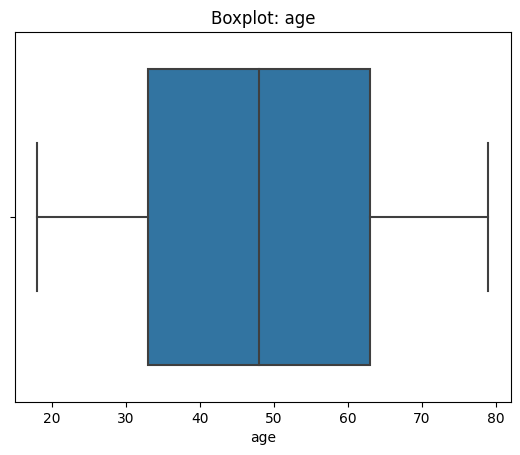

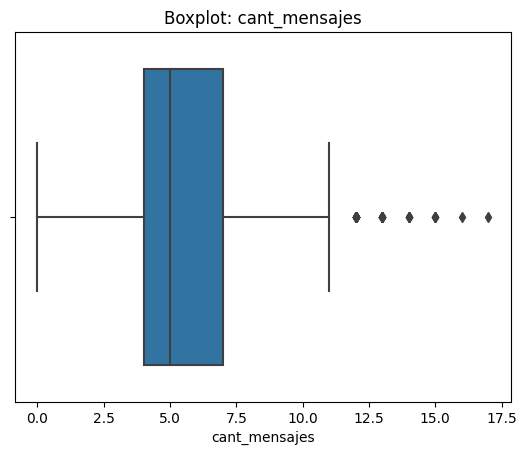

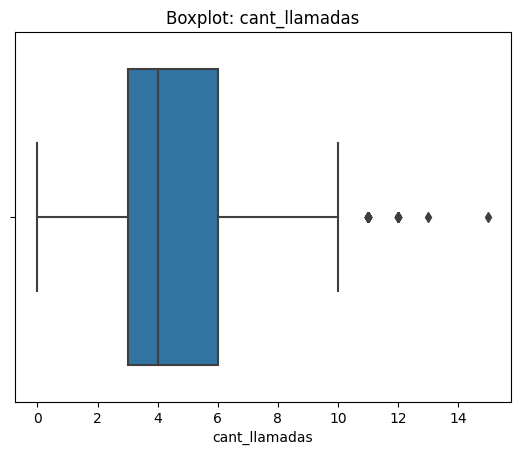

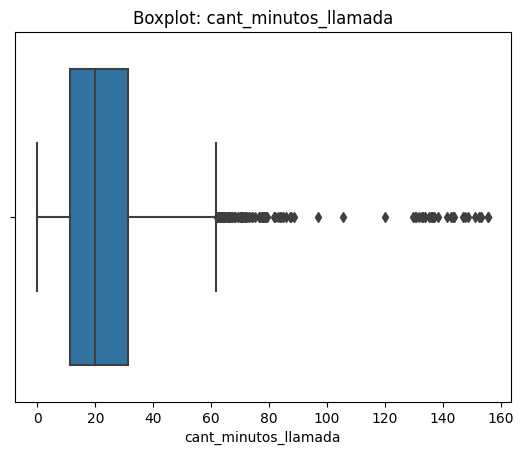

In [212]:


# Visualizando usando BoxPlot 

for col in columnas_numericas:
    sns.boxplot(data=user_profile ,x=col, hue='plan')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()



💡Insights: 
- Age: ...(presenta o no outliers)
- cant_mensajes: ...
- cant_llamadas: ...
- cant_minutos_llamada: ...

In [213]:

# Calculamos límites con el método IQR
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    print(f'{col}: límite inferior = {limite_inferior:.2f}, '
          f'límite superior = {limite_superior:.2f}')

age: límite inferior = -12.00, límite superior = 108.00
cant_mensajes: límite inferior = -0.50, límite superior = 11.50
cant_llamadas: límite inferior = -1.50, límite superior = 10.50
cant_minutos_llamada: límite inferior = -19.31, límite superior = 61.83


In [214]:

# Revisamos los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3960.000000,3959.000000,3959.000000,3959.000000
mean,48.119444,5.525385,4.483708,23.331074
std,17.686962,2.359503,2.143459,18.199917
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.790000
75%,63.000000,7.000000,6.000000,31.405000
max,79.000000,17.000000,15.000000,155.690000



💡 Insights: identificación y tratamiento de outliers

age: No se identifican outliers mediante el método IQR. Los límites calculados son -12 y 108 años, mientras que las edades observadas están entre 18 y 79 años. Se propone mantener todos los registros, ya que se encuentran dentro del rango esperado.

cant_mensajes: Se identifican posibles outliers superiores, porque el máximo de 17 mensajes supera el límite de 11,5. Se propone mantenerlos, ya que pueden representar usuarios con un uso elevado y no hay evidencia de que sean errores.

cant_llamadas: Se identifican posibles outliers superiores, dado que el máximo de 15 llamadas supera el límite de 10,5. Se propone conservarlos, porque podrían corresponder a hábitos reales de consumo.

cant_minutos_llamada: Se identifican posibles outliers superiores, ya que el máximo de 155,69 minutos supera ampliamente el límite de 61,83. Se recomienda conservarlos provisionalmente y revisarlos, porque podrían representar usuarios con un consumo elevado. No hay evidencia suficiente para justificar su eliminación.



In [215]:
# Creamos una columna grupo_uso definiendo una funcion para aplicar condiciones

def clasificar_uso(row):
    if pd.isna(row['cant_llamadas']) or pd.isna(row['cant_mensajes']):
        return pd.NA
    elif row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'
        
user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1) 

In [216]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


In [217]:
user_profile['grupo_uso'].value_counts()

Uso medio    2917
Bajo uso      766
Alto uso      276
Name: grupo_uso, dtype: int64

In [218]:
# Creamos columna grupo_edad

def clasificar_edad(row):
    if pd.isna(row['age']):
        return pd.NA
    elif row['age'] < 30:
        return 'Joven'
    elif row['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)

In [219]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


In [220]:

user_profile['grupo_edad'].value_counts()

Adulto          2000
Adulto Mayor    1209
Joven            751
Name: grupo_edad, dtype: int64

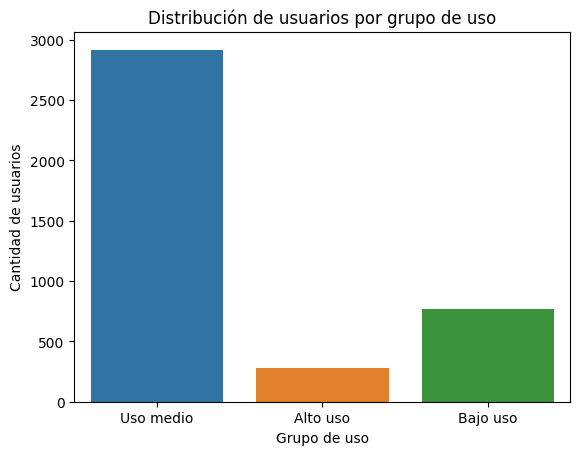

In [221]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')

plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()


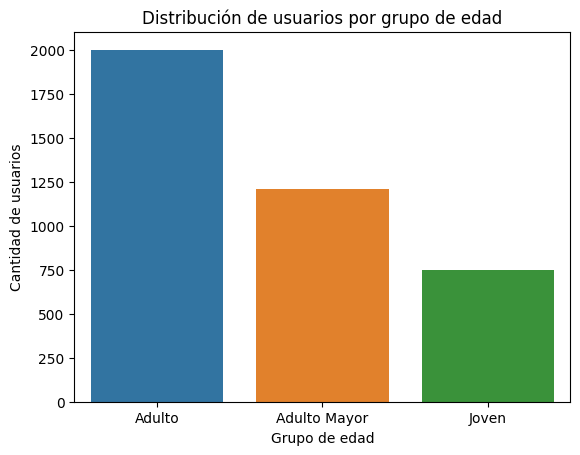

In [222]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')

plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')

plt.show()


In [223]:
##controlamos que los valores nulos no hayan sido asignados a ningun grupo de edad o de uso

user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada', 'grupo_edad', 'grupo_uso']].isna().sum()


age                     40
cant_mensajes           41
cant_llamadas           41
cant_minutos_llamada    41
grupo_edad              40
grupo_uso               41
dtype: int64

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
-Se encontraron 40 valores faltantes en age (1 % de los registros) y 41 en cada una de las variables de uso (cant_mensajes, cant_llamadas y cant_minutos_llamada), equivalentes al 1,03 % de los registros por columna. Para evitar clasificaciones incorrectas, los usuarios sin información suficiente quedaron sin asignación de grupo.

-Se identificaron valores atípicos en las métricas de uso según el método del rango intercuartílico (IQR). Estos valores se conservaron porque podrían representar comportamientos reales y conviene investigarlos antes de decidir si requieren corrección o un tratamiento especial.


🔍 **Segmentos por Edad**
-Entre los 3.960 usuarios clasificados, el 50,51 % son adultos de 30 a 59 años (2.000 usuarios), el 30,53 % son adultos mayores de 60 años (1.209) y el 18,96 % son jóvenes menores de 30 años (751).

-La concentración de clientes adultos representa una oportunidad para evaluar planes ajustados a sus patrones de consumo. La presencia significativa de adultos mayores también justifica analizar sus necesidades, sin asumir que la edad por sí sola determina sus preferencias o su rentabilidad. 


📊 **Segmentos por Nivel de Uso**
-De los 3.959 usuarios clasificados, el 73,68 % presenta uso medio (2.917 usuarios), el 19,35 % bajo uso (766) y el 6,97 % alto uso (276).

-El predominio del uso medio sugiere que conviene evaluar si los planes actuales se ajustan al consumo habitual de la mayoría. El segmento de bajo uso podría ser una oportunidad para investigar barreras de consumo, mientras que los usuarios de alto uso podrían beneficiarse de paquetes con mayores cantidades de llamadas y mensajes.

➡️ En conjunto, los resultados permiten identificar perfiles de consumo y orientar nuevas hipótesis comerciales. Sin embargo, todavía no permiten determinar qué segmentos generan mayores ingresos, son más rentables o presentan mayor riesgo de cancelación.


💡 **Recomendaciones**
-Evaluar planes económicos o flexibles para clientes de bajo uso y paquetes de mayor capacidad para usuarios de alto uso.

-Cruzar grupo_edad con grupo_uso para identificar combinaciones de edad y consumo que permitan diseñar ofertas más específicas.

-Investigar los valores atípicos de llamadas, mensajes y minutos para distinguir consumos legítimos de posibles errores de registro.

-Comparar los segmentos con el plan contratado, los ingresos y la cancelación para priorizar las oportunidades comerciales según su impacto real.

-Medir los resultados de cualquier cambio de planes mediante indicadores de consumo, ingresos por cliente y tasa de cancelación.